# Leaf/Plant Segmentation Model

Trains a binary (plant vs. background) segmentation model so that brand-new, unannotated
photos can be automatically masked before being classified by the leaf-focused ResNet50
(`checkpoints_masked/resnet50_masked_best.pt`). The earlier masked-vs-original comparison
used ground-truth COCO polygons to build masks -- those don't exist for new photos, so this
notebook trains a model to predict them instead.

Target masks are built by unioning every polygon on an image (regardless of growth-stage
category) from `tomato final dataset/<split>/_annotations.coco.json` into one binary mask.
Architecture: DeepLabV3 with a ResNet50 backbone (torchvision, COCO-pretrained), fine-tuned
for 2-class (background/plant) per-pixel segmentation.

This notebook is fully additive -- it does not modify resnet50.ipynb, dataset_utils.py,
resnet50_masked_comparison.ipynb, dataset/, export/, checkpoints/, or checkpoints_masked/.

In [1]:
import os
import copy
import time
import random

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision.transforms import v2
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights
from torchvision import models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

ModuleNotFoundError: No module named 'torch'

In [2]:
# ---- Config ----
PROJECT_ROOT = r"d:\Reasearch\Resnet50test"
import sys; sys.path.insert(0, os.path.join(PROJECT_ROOT, "src"))  # helper modules live in src/
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results"); os.makedirs(RESULTS_DIR, exist_ok=True)
DATA_DIR = os.path.join(PROJECT_ROOT, "tomato final dataset")
SEG_CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, "checkpoints_segmentation")
os.makedirs(SEG_CHECKPOINT_DIR, exist_ok=True)

CLASSIFIER_CHECKPOINT_PATH = os.path.join(PROJECT_ROOT, "checkpoints_masked", "resnet50_masked_best.pt")

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_EPOCHS = 15
LEARNING_RATE = 1e-4
NUM_WORKERS = 4

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

## 1. Data loading

`CocoPlantSegmentationDataset` (in `segmentation_dataset_utils.py`) rasterizes every
polygon on an image into one binary mask (1=plant, 0=background) and returns it alongside
the image. Uses `torchvision.transforms.v2` with `tv_tensors` so random crop/flip/rotation
are applied identically to the image and its mask -- plain `transforms.Compose` applied
separately to each would pick different random parameters and misalign them. Color
jitter/normalize apply only to the image; the mask stays untouched integer labels.

In [5]:
from segmentation_dataset_utils import CocoPlantSegmentationDataset

train_joint_transform = v2.Compose([
    v2.RandomResizedCrop(IMAGE_SIZE, scale=(0.8, 1.0), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.RandomRotation(15),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_joint_transform = v2.Compose([
    v2.Resize(int(IMAGE_SIZE * 1.14), antialias=True),
    v2.CenterCrop(IMAGE_SIZE),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds = CocoPlantSegmentationDataset(DATA_DIR, "train", train_joint_transform)
val_ds = CocoPlantSegmentationDataset(DATA_DIR, "valid", eval_joint_transform, classes=train_ds.classes)
test_ds = CocoPlantSegmentationDataset(DATA_DIR, "test", eval_joint_transform, classes=train_ds.classes)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}  (images with no annotation skipped)")

_PERSIST = NUM_WORKERS > 0
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                           pin_memory=True, persistent_workers=_PERSIST)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                         pin_memory=True, persistent_workers=_PERSIST)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                          pin_memory=True, persistent_workers=_PERSIST)

Train: 684 | Val: 135 | Test: 160  (images with no annotation skipped)


## 2. Sanity-check a batch

Confirms masks line up with the plant region after augmentation.

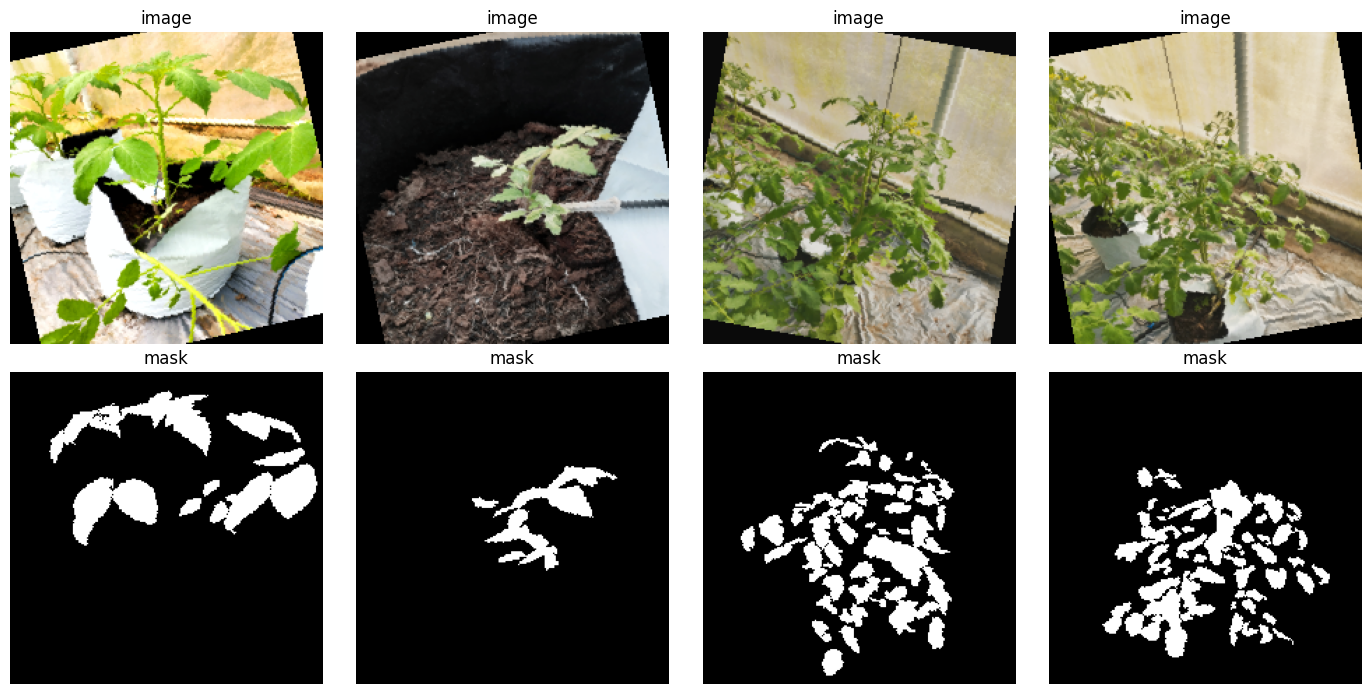

In [6]:
def denormalize(img_tensor):
    img = img_tensor.cpu().numpy().transpose(1, 2, 0)
    img = img * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(img, 0, 1)

images, masks = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    axes[0, i].imshow(denormalize(images[i]))
    axes[0, i].set_title("image")
    axes[0, i].axis("off")
    axes[1, i].imshow(masks[i].numpy(), cmap="gray")
    axes[1, i].set_title("mask")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

## 3. Model — DeepLabV3-ResNet50, binary segmentation head

Loads the COCO-pretrained DeepLabV3-ResNet50 and replaces the final 1x1 conv (and the
auxiliary head's) with a 2-class (background/plant) version. The aux head's output is
ignored at inference; only used here if `AUX_LOSS_WEIGHT > 0` during training.

In [7]:
AUX_LOSS_WEIGHT = 0.4

def build_segmentation_model():
    m = deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT)
    m.classifier[4] = nn.Conv2d(256, 2, kernel_size=1)
    if m.aux_classifier is not None:
        m.aux_classifier[4] = nn.Conv2d(256, 2, kernel_size=1)
    return m.to(device)

seg_model = build_segmentation_model()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(seg_model.parameters(), lr=LEARNING_RATE)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

n_params = sum(p.numel() for p in seg_model.parameters() if p.requires_grad)
print(f"Trainable params: {n_params:,}")

Trainable params: 41,994,308


## 4. Training loop

Tracks per-pixel loss and mean IoU (background + plant classes) each epoch; saves the
checkpoint with the best validation IoU.

In [8]:
def mean_iou(preds, targets, num_classes=2):
    ious = []
    for c in range(num_classes):
        pred_c = preds == c
        target_c = targets == c
        intersection = (pred_c & target_c).sum().item()
        union = (pred_c | target_c).sum().item()
        if union == 0:
            continue
        ious.append(intersection / union)
    return sum(ious) / len(ious) if ious else 0.0


def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    running_loss, total, iou_sum, n_batches = 0.0, 0, 0.0, 0
    with torch.set_grad_enabled(is_train):
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            if is_train:
                optimizer.zero_grad()

            output = model(images)
            loss = criterion(output["out"], masks)
            if is_train and model.aux_classifier is not None:
                loss = loss + AUX_LOSS_WEIGHT * criterion(output["aux"], masks)

            if is_train:
                loss.backward()
                optimizer.step()

            preds = output["out"].argmax(dim=1)
            running_loss += loss.item() * images.size(0)
            total += images.size(0)
            iou_sum += mean_iou(preds, masks)
            n_batches += 1

    return running_loss / total, iou_sum / n_batches

In [9]:
history = {"train_loss": [], "train_iou": [], "val_loss": [], "val_iou": []}
best_val_iou = 0.0
best_model_wts = copy.deepcopy(seg_model.state_dict())
best_ckpt_path = os.path.join(SEG_CHECKPOINT_DIR, "deeplabv3_leaf_seg_best.pt")

start = time.time()
for epoch in range(1, NUM_EPOCHS + 1):
    train_loss, train_iou = run_epoch(seg_model, train_loader, criterion, optimizer)
    val_loss, val_iou = run_epoch(seg_model, val_loader, criterion, optimizer=None)
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_iou"].append(train_iou)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)

    if val_iou > best_val_iou:
        best_val_iou = val_iou
        best_model_wts = copy.deepcopy(seg_model.state_dict())
        torch.save({
            "model_state_dict": best_model_wts,
            "epoch": epoch,
            "val_iou": val_iou,
        }, best_ckpt_path)

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
          f"train_loss {train_loss:.4f} train_iou {train_iou:.4f} | "
          f"val_loss {val_loss:.4f} val_iou {val_iou:.4f}")

elapsed = time.time() - start
print(f"\nTraining complete in {elapsed // 60:.0f}m {elapsed % 60:.0f}s")
print(f"Best val IoU: {best_val_iou:.4f} (saved to {best_ckpt_path})")

seg_model.load_state_dict(best_model_wts)
seg_model.eval()

Epoch 01/15 | train_loss 0.6877 train_iou 0.5756 | val_loss 0.3900 val_iou 0.6587
Epoch 02/15 | train_loss 0.4101 train_iou 0.6813 | val_loss 0.2383 val_iou 0.7216
Epoch 03/15 | train_loss 0.3311 train_iou 0.7176 | val_loss 0.2209 val_iou 0.7550
Epoch 04/15 | train_loss 0.2959 train_iou 0.7318 | val_loss 0.1857 val_iou 0.7534
Epoch 05/15 | train_loss 0.2715 train_iou 0.7424 | val_loss 0.1728 val_iou 0.7759
Epoch 06/15 | train_loss 0.2564 train_iou 0.7485 | val_loss 0.1702 val_iou 0.7721
Epoch 07/15 | train_loss 0.2400 train_iou 0.7582 | val_loss 0.1664 val_iou 0.7844
Epoch 08/15 | train_loss 0.2309 train_iou 0.7622 | val_loss 0.1570 val_iou 0.7851
Epoch 09/15 | train_loss 0.2248 train_iou 0.7625 | val_loss 0.1541 val_iou 0.7875
Epoch 10/15 | train_loss 0.2158 train_iou 0.7704 | val_loss 0.1626 val_iou 0.7868
Epoch 11/15 | train_loss 0.2101 train_iou 0.7737 | val_loss 0.1565 val_iou 0.7932
Epoch 12/15 | train_loss 0.2035 train_iou 0.7776 | val_loss 0.1544 val_iou 0.7965
Epoch 13/15 | tr

DeepLabV3(
  (backbone): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Se

In [ ]:
best_ckpt_path = os.path.join(SEG_CHECKPOINT_DIR, "deeplabv3_leaf_seg_best.pt")
ckpt = torch.load(best_ckpt_path, map_location=device, weights_only=False)
seg_model.load_state_dict(ckpt["model_state_dict"])
seg_model.eval()
print("Loaded checkpoint, val IoU:", ckpt["val_iou"])


## 5. Training curves

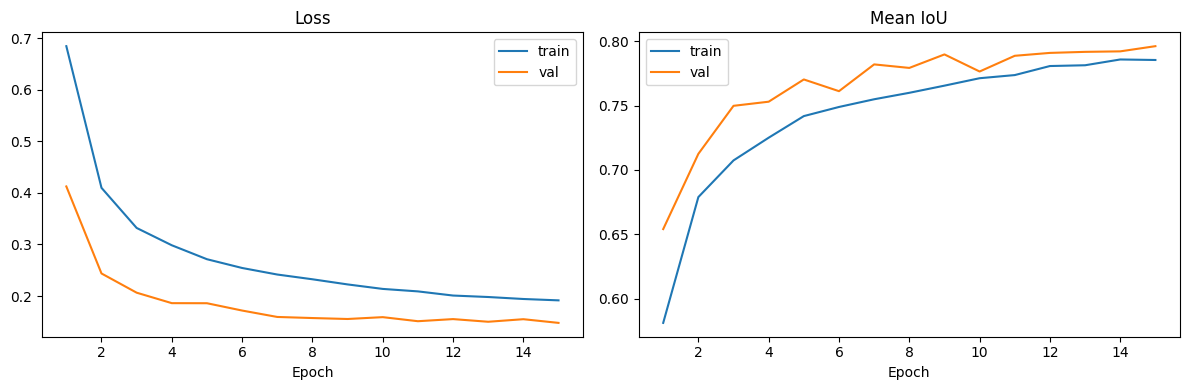

In [11]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_range, history["train_loss"], label="train")
axes[0].plot(epochs_range, history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_range, history["train_iou"], label="train")
axes[1].plot(epochs_range, history["val_iou"], label="val")
axes[1].set_title("Mean IoU")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Evaluation on the held-out test set

Reports mean IoU on `tomato final dataset/test` (never used for training or model
selection) and shows a few predicted-mask vs. ground-truth-mask examples.

Test loss: 0.2273 | Test mean IoU: 0.7548


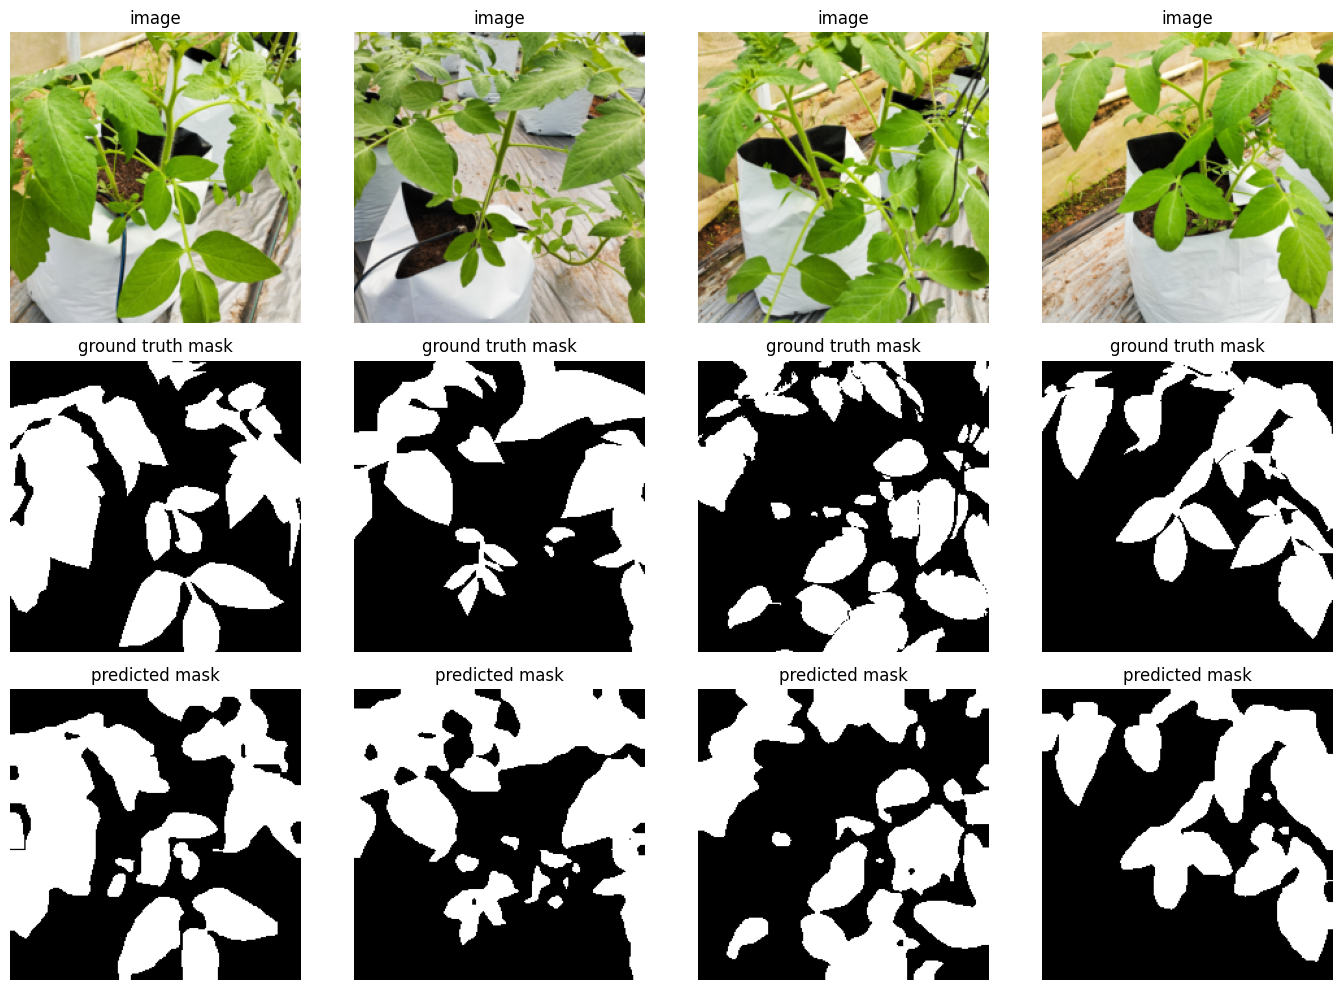

In [12]:
test_loss, test_iou = run_epoch(seg_model, test_loader, criterion, optimizer=None)
print(f"Test loss: {test_loss:.4f} | Test mean IoU: {test_iou:.4f}")

images, masks = next(iter(test_loader))
with torch.no_grad():
    preds = seg_model(images.to(device))["out"].argmax(dim=1).cpu()

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for i in range(4):
    axes[0, i].imshow(denormalize(images[i]))
    axes[0, i].set_title("image")
    axes[0, i].axis("off")
    axes[1, i].imshow(masks[i].numpy(), cmap="gray")
    axes[1, i].set_title("ground truth mask")
    axes[1, i].axis("off")
    axes[2, i].imshow(preds[i].numpy(), cmap="gray")
    axes[2, i].set_title("predicted mask")
    axes[2, i].axis("off")
plt.tight_layout()
plt.show()

## 7. Full two-stage pipeline: segment (predicted mask) -> mask -> classify

This is the realistic, deployable number: unlike the earlier masked-vs-original comparison
(which used perfect ground-truth polygons), this evaluates the classifier on masks
*predicted* by this segmentation model -- exactly what would happen on a brand-new photo
with no annotations. Uses raw (unmasked, unnormalized) test images so the predicted mask
can be applied to pixel values directly, matching how `generate_masked_dataset.py` built
the training data for the masked classifier.

In [ ]:
import torch.nn.functional as F
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from masked_comparison_utils import SplitFirstFolderDataset

CLASS_NAMES = ["developing", "flowering", "fruiting", "seeding"]

# Raw (0-1, unnormalized) tensors so we can apply the predicted mask to pixel values,
# then re-normalize before feeding the classifier -- mirrors generate_masked_dataset.py.
raw_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
])
normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)

test_ds_raw = SplitFirstFolderDataset(DATA_DIR, "test", raw_transform, classes=CLASS_NAMES)
# num_workers=0: this is a single one-off pass over 160 test images -- not worth spinning up
# another persistent worker pool on top of the 3 already alive from Section 1 (train/val/test
# loaders, NUM_WORKERS=4 each, persistent_workers=True) -- doing so previously stalled this
# cell for 40+ minutes on this 15GB-RAM machine instead of the <1min it should take.
test_loader_raw = DataLoader(test_ds_raw, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

def load_masked_classifier():
    m = models.resnet50(weights=None)
    m.fc = nn.Linear(m.fc.in_features, len(CLASS_NAMES))
    ckpt = torch.load(CLASSIFIER_CHECKPOINT_PATH, map_location=device, weights_only=False)
    m.load_state_dict(ckpt["model_state_dict"])
    return m.to(device).eval()

classifier = load_masked_classifier()
seg_model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for raw_images, labels in test_loader_raw:
        raw_images = raw_images.to(device)

        norm_images = normalize(raw_images)
        pred_masks = seg_model(norm_images)["out"].argmax(dim=1, keepdim=True).float()  # B,1,H,W

        masked_raw = raw_images * pred_masks  # black out predicted background
        masked_norm = normalize(masked_raw)

        outputs = classifier(masked_norm)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy() if hasattr(labels, "numpy") else labels)

pipeline_acc = (np.array(all_preds) == np.array(all_labels)).mean()
print(f"Full pipeline (predicted-mask) test accuracy: {pipeline_acc:.4f}")
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Full pipeline (segment -> mask -> classify), acc={pipeline_acc:.4f}")
plt.tight_layout()
plt.show()

print(f"\nFor reference: oracle ground-truth-mask accuracy (from resnet50_masked_comparison.ipynb) was 0.9187")
print(f"Gap from oracle: {0.9187 - pipeline_acc:+.4f}")

## 8. Export

Exports the segmentation model and a combined standalone inference script (segment ->
mask -> classify) for the fusion project, into `export_leaf_pipeline/`.

In [14]:
import json
import datetime

EXPORT_DIR = os.path.join(PROJECT_ROOT, "export_leaf_pipeline")
os.makedirs(EXPORT_DIR, exist_ok=True)

seg_ckpt = torch.load(best_ckpt_path, map_location="cpu", weights_only=False)
# Drop aux_classifier.* weights before export: deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT)
# (training, cell 8) auto-enables aux_loss so its state_dict includes an aux head, but leaf_pipeline.py's
# load_leaf_pipeline() builds with deeplabv3_resnet50(weights=None) (no aux_classifier submodule at all),
# and the aux head is unused at inference anyway. Stripping avoids a load_state_dict key mismatch.
seg_state_no_aux = {k: v for k, v in seg_ckpt["model_state_dict"].items() if not k.startswith("aux_classifier.")}
torch.save(seg_state_no_aux, os.path.join(EXPORT_DIR, "deeplabv3_leaf_seg.pth"))

classifier_ckpt = torch.load(CLASSIFIER_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
torch.save(classifier_ckpt["model_state_dict"], os.path.join(EXPORT_DIR, "resnet50_leaf_classifier.pth"))

metadata = {
    "pipeline": "segment (DeepLabV3-ResNet50, binary plant/background) -> mask raw image -> "
                "classify (ResNet50, trained on masked images)",
    "segmentation_model": {
        "architecture": "deeplabv3_resnet50",
        "num_classes": 2,
        "class_meaning": {"0": "background", "1": "plant/leaf"},
        "best_epoch": int(seg_ckpt["epoch"]),
        "val_iou_at_best_epoch": float(seg_ckpt["val_iou"]),
        "test_mean_iou": float(test_iou),
    },
    "classifier_model": {
        "architecture": "resnet50",
        "num_classes": len(CLASS_NAMES),
        "class_names": CLASS_NAMES,
        "trained_on": "tomato final dataset_masked (ground-truth-masked images)",
    },
    "input_size": [224, 224, 3],
    "normalization": {"mean": IMAGENET_MEAN, "std": IMAGENET_STD},
    "full_pipeline_test_accuracy": float(pipeline_acc),
    "oracle_ground_truth_mask_test_accuracy": 0.9187,
    "note": "full_pipeline_test_accuracy uses masks PREDICTED by the segmentation model "
            "(realistic, deployable number for new/unannotated photos); the oracle figure "
            "used perfect ground-truth polygon masks and is not achievable on new images.",
    "training_date": datetime.date.today().isoformat(),
    "framework": {"torch": torch.__version__, "torchvision": __import__("torchvision").__version__},
}
with open(os.path.join(EXPORT_DIR, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Exported to", EXPORT_DIR)

Exported to d:\Reasearch\Resnet50test\export_leaf_pipeline


In [15]:
pipeline_code = '''"""Standalone leaf-focused tomato growth-stage inference pipeline.
Segments the plant/leaf region out of a raw photo, blacks out the background, then
classifies growth stage. No dependency on this project\'s training code -- copy-paste
into another project alongside deeplabv3_leaf_seg.pth and resnet50_leaf_classifier.pth.
"""
import torch
import torch.nn as nn
from torchvision import transforms, models
from torchvision.models.segmentation import deeplabv3_resnet50

CLASS_NAMES = {class_names!r}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

RAW_TRANSFORM = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
])
NORMALIZE = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)


def load_leaf_pipeline(seg_checkpoint_path, classifier_checkpoint_path, device=None):
    """Returns (segmentation_model, classifier_model), both in eval() mode on device."""
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    device = torch.device(device) if not isinstance(device, torch.device) else device

    seg_model = deeplabv3_resnet50(weights=None)
    seg_model.classifier[4] = nn.Conv2d(256, 2, kernel_size=1)
    if seg_model.aux_classifier is not None:
        seg_model.aux_classifier[4] = nn.Conv2d(256, 2, kernel_size=1)
    seg_state = torch.load(seg_checkpoint_path, map_location=device, weights_only=True)
    seg_model.load_state_dict(seg_state)
    seg_model = seg_model.to(device).eval()

    classifier = models.resnet50(weights=None)
    classifier.fc = nn.Linear(classifier.fc.in_features, len(CLASS_NAMES))
    clf_state = torch.load(classifier_checkpoint_path, map_location=device, weights_only=True)
    classifier.load_state_dict(clf_state)
    classifier = classifier.to(device).eval()

    return seg_model, classifier


def predict_growth_stage(image_pil, seg_model, classifier, device=None):
    """image_pil: a PIL.Image (RGB). Returns (predicted_class_name, probs_dict)."""
    if device is None:
        device = next(classifier.parameters()).device

    raw = RAW_TRANSFORM(image_pil.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        norm = NORMALIZE(raw)
        pred_mask = seg_model(norm)["out"].argmax(dim=1, keepdim=True).float()
        masked_raw = raw * pred_mask
        masked_norm = NORMALIZE(masked_raw)
        logits = classifier(masked_norm)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    pred_idx = int(probs.argmax())
    return CLASS_NAMES[pred_idx], dict(zip(CLASS_NAMES, probs.tolist()))
'''.format(class_names=CLASS_NAMES)

with open(os.path.join(EXPORT_DIR, "leaf_pipeline.py"), "w", encoding="utf-8") as f:
    f.write(pipeline_code)

print("Wrote", os.path.join(EXPORT_DIR, "leaf_pipeline.py"))

Wrote d:\Reasearch\Resnet50test\export_leaf_pipeline\leaf_pipeline.py


In [16]:
# Fresh-process sanity test of the exported pipeline on a few test images
import importlib.util
spec = importlib.util.spec_from_file_location("leaf_pipeline", os.path.join(EXPORT_DIR, "leaf_pipeline.py"))
leaf_pipeline = importlib.util.module_from_spec(spec)
spec.loader.exec_module(leaf_pipeline)

seg_m, clf_m = leaf_pipeline.load_leaf_pipeline(
    os.path.join(EXPORT_DIR, "deeplabv3_leaf_seg.pth"),
    os.path.join(EXPORT_DIR, "resnet50_leaf_classifier.pth"),
)

from PIL import Image as PILImage
sample_paths = [
    (os.path.join(DATA_DIR, "test", "developing"), "developing"),
    (os.path.join(DATA_DIR, "test", "flowering"), "flowering"),
    (os.path.join(DATA_DIR, "test", "fruiting"), "fruiting"),
    (os.path.join(DATA_DIR, "test", "seeding"), "seeding"),
]
for folder, true_label in sample_paths:
    fname = sorted(f for f in os.listdir(folder) if f.lower().endswith(".jpg"))[0]
    img = PILImage.open(os.path.join(folder, fname))
    pred_label, probs = leaf_pipeline.predict_growth_stage(img, seg_m, clf_m)
    print(f"true={true_label:<12} pred={pred_label:<12} probs={ {k: round(v,3) for k,v in probs.items()} }")

true=developing   pred=developing   probs={'developing': 1.0, 'flowering': 0.0, 'fruiting': 0.0, 'seeding': 0.0}
true=flowering    pred=flowering    probs={'developing': 0.407, 'flowering': 0.572, 'fruiting': 0.018, 'seeding': 0.003}
true=fruiting     pred=flowering    probs={'developing': 0.101, 'flowering': 0.782, 'fruiting': 0.112, 'seeding': 0.004}
true=seeding      pred=seeding      probs={'developing': 0.002, 'flowering': 0.001, 'fruiting': 0.001, 'seeding': 0.997}


In [17]:
# ==== Train / Valid / Test accuracy summary ====

# --- Segmentation model: pixel-level accuracy + mean IoU, all 3 splits ---
def pixel_accuracy_and_iou(model, loader):
    model.eval()
    correct, total = 0, 0
    iou_sum, n_batches = 0.0, 0
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            preds = model(images)["out"].argmax(dim=1)
            correct += (preds == masks).sum().item()
            total += masks.numel()
            iou_sum += mean_iou(preds, masks)
            n_batches += 1
    return correct / total, iou_sum / n_batches

seg_train_acc, seg_train_iou = pixel_accuracy_and_iou(seg_model, train_loader)
seg_val_acc, seg_val_iou = pixel_accuracy_and_iou(seg_model, val_loader)
seg_test_acc, seg_test_iou = pixel_accuracy_and_iou(seg_model, test_loader)

print("=== Segmentation model (plant vs. background, pixel-level) ===")
print(f"Train: pixel_accuracy={seg_train_acc:.4f}  mean_IoU={seg_train_iou:.4f}")
print(f"Valid: pixel_accuracy={seg_val_acc:.4f}  mean_IoU={seg_val_iou:.4f}")
print(f"Test:  pixel_accuracy={seg_test_acc:.4f}  mean_IoU={seg_test_iou:.4f}")

# --- Leaf classifier: growth-stage accuracy on masked images, all 3 splits ---
DATA_DIR_MASKED = os.path.join(PROJECT_ROOT, "tomato final dataset_masked")
clf_eval_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

clf_train_ds = SplitFirstFolderDataset(DATA_DIR_MASKED, "train", clf_eval_transform, classes=CLASS_NAMES)
clf_val_ds = SplitFirstFolderDataset(DATA_DIR_MASKED, "valid", clf_eval_transform, classes=CLASS_NAMES)
clf_test_ds = SplitFirstFolderDataset(DATA_DIR_MASKED, "test", clf_eval_transform, classes=CLASS_NAMES)

clf_train_loader = DataLoader(clf_train_ds, batch_size=BATCH_SIZE, shuffle=False)
clf_val_loader = DataLoader(clf_val_ds, batch_size=BATCH_SIZE, shuffle=False)
clf_test_loader = DataLoader(clf_test_ds, batch_size=BATCH_SIZE, shuffle=False)

def classifier_accuracy(clf, loader):
    clf.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            preds = clf(images).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return correct / total

clf_train_acc = classifier_accuracy(classifier, clf_train_loader)
clf_val_acc = classifier_accuracy(classifier, clf_val_loader)
clf_test_acc = classifier_accuracy(classifier, clf_test_loader)

print("\n=== Leaf classifier (growth stage, on ground-truth-masked images) ===")
print(f"Train: accuracy={clf_train_acc:.4f}")
print(f"Valid: accuracy={clf_val_acc:.4f}")
print(f"Test:  accuracy={clf_test_acc:.4f}")

# --- Full two-stage pipeline: already computed as pipeline_acc (test-only, ---
# --- since it's the deployable number -- train/valid don't apply the same way) ---
print("\n=== Full pipeline (segment -> mask -> classify), on RAW/unmasked images ===")
print(f"Test:  accuracy={pipeline_acc:.4f}   <- the realistic, deployable number")

=== Segmentation model (plant vs. background, pixel-level) ===
Train: pixel_accuracy=0.9440  mean_IoU=0.7971
Valid: pixel_accuracy=0.9365  mean_IoU=0.7963
Test:  pixel_accuracy=0.9022  mean_IoU=0.7548

=== Leaf classifier (growth stage, on ground-truth-masked images) ===
Train: accuracy=0.9810
Valid: accuracy=0.9778
Test:  accuracy=0.9187

=== Full pipeline (segment -> mask -> classify), on RAW/unmasked images ===
Test:  accuracy=0.8438   <- the realistic, deployable number


In [ ]:
# ---- Shared metric helpers (Accuracy/Precision/Recall/F1) for the CV sections below
# and the final summary cell at the end of the notebook ----
#
# Segmentation is scored by accumulating a (true x pred) PIXEL confusion matrix batch-by-batch,
# never materializing full-resolution predictions/targets for every image at once -- that
# per-image-array pattern is what caused a MemoryError earlier in this notebook (Section 10's
# FoldSegDataset). A 2x2 int matrix per model is a few bytes regardless of dataset size.
from sklearn.metrics import precision_recall_fscore_support


def pixel_confusion_counts(model, loader, num_classes=2):
    model.eval()
    counts = np.zeros((num_classes, num_classes), dtype=np.int64)  # rows=true, cols=pred
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            preds = model(images)["out"].argmax(dim=1)
            for t in range(num_classes):
                for p in range(num_classes):
                    counts[t, p] += int(((masks == t) & (preds == p)).sum().item())
    return counts


def classification_metrics_from_confusion(counts, class_names=None):
    """accuracy + per-class/macro precision, recall, F1 from a (true x pred) confusion matrix."""
    counts = np.asarray(counts, dtype=np.float64)
    n = counts.shape[0]
    class_names = class_names or [str(i) for i in range(n)]
    total = counts.sum()
    accuracy = float(np.trace(counts) / total) if total > 0 else 0.0
    per_class, precisions, recalls, f1s = {}, [], [], []
    for c in range(n):
        tp = counts[c, c]
        fp = counts[:, c].sum() - tp
        fn = counts[c, :].sum() - tp
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        per_class[class_names[c]] = {"precision": precision, "recall": recall, "f1": f1}
        precisions.append(precision)
        recalls.append(recall)
        f1s.append(f1)
    return {
        "accuracy": accuracy,
        "precision_macro": float(np.mean(precisions)),
        "recall_macro": float(np.mean(recalls)),
        "f1_macro": float(np.mean(f1s)),
        "per_class": per_class,
    }


## 9. K-Fold Cross-Validation of the DeepLabV3 Segmentation Model Only

Segmentation-only CV: unlike Section 10 below, this does **not** retrain the classifier --
it only cross-validates the DeepLabV3 segmenter itself (mean IoU) across 5 folds built from
all annotated images pooled across the original train/valid/test splits. Each fold trains a
fresh segmenter from the COCO-pretrained backbone (no leakage across folds), holds out an
inner validation split for checkpoint selection, and reports IoU on the fold's held-out test
images. Much faster than Section 10 since only one model is retrained per fold.

**Requires:** cells 1-11 above already run once (reuses `build_segmentation_model`,
`run_epoch`, `train_joint_transform`, `eval_joint_transform`, `device`, etc. from this
notebook's own state).


In [ ]:
# ---- K-Fold Cross-Validation -- DeepLabV3 Segmentation Model ONLY ----
import json
import copy
import cv2
import numpy as np
import pandas as pd
from PIL import Image as PILImage
from torchvision import tv_tensors
from sklearn.model_selection import KFold, train_test_split
from segmentation_dataset_utils import build_binary_mask


N_FOLDS = 5
SEG_EPOCHS_CV = 10
SEG_BATCH_SIZE_CV = BATCH_SIZE
INNER_VAL_FRACTION = 0.15


def build_filename_index(split):
    folder = os.path.join(DATA_DIR, split)
    index = {}
    for root, dirs, files in os.walk(folder):
        for f in files:
            index[f] = os.path.join(root, f)
    return index


def load_split_annotations(split):
    json_path = os.path.join(DATA_DIR, split, "_annotations.coco.json")
    with open(json_path, encoding="utf-8") as f:
        coco = json.load(f)
    anns_by_image_id = {}
    for ann in coco["annotations"]:
        anns_by_image_id.setdefault(ann["image_id"], []).append(ann)

    filename_index = build_filename_index(split)
    samples = []
    missing = 0
    for im in coco["images"]:
        anns = anns_by_image_id.get(im["id"], [])
        if not anns:
            continue
        path = filename_index.get(im["file_name"])
        if path is None:
            missing += 1
            continue
        samples.append({
            "path": path,
            "anns": anns,
            "height": im["height"],
            "width": im["width"],
        })
    if missing:
        print(f"  [{split}] skipped {missing} annotated images with missing files")
    return samples


all_samples = []
for split in ["train", "valid", "test"]:
    all_samples.extend(load_split_annotations(split))

print(f"Unified CV pool: {len(all_samples)} annotated images")


class FoldSegDataset(torch.utils.data.Dataset):
    def __init__(self, samples, joint_transform):
        self.samples = samples
        self.joint_transform = joint_transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        img = PILImage.open(s["path"]).convert("RGB")
        img.thumbnail((1024, 1024), PILImage.LANCZOS)
        img_w, img_h = img.size

        mask = build_binary_mask(s["height"], s["width"], s["anns"])
        mask = np.asarray(mask).astype(np.uint8)
        if mask.ndim > 2:
            mask = mask.squeeze()
        if mask.shape[1] != img_w or mask.shape[0] != img_h:
            mask = cv2.resize(mask, (img_w, img_h), interpolation=cv2.INTER_NEAREST)

        img_tv = tv_tensors.Image(img)
        mask_tv = tv_tensors.Mask(mask)
        img_tv, mask_tv = self.joint_transform(img_tv, mask_tv)
        return img_tv, mask_tv.squeeze(0).long()


kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_results = []

for fold_i, (trainval_idx, test_idx) in enumerate(kf.split(all_samples), start=1):
    trainval_samples = [all_samples[i] for i in trainval_idx]
    test_samples = [all_samples[i] for i in test_idx]

    inner_train_idx, inner_val_idx = train_test_split(
        range(len(trainval_samples)), test_size=INNER_VAL_FRACTION, random_state=SEED
    )
    train_samples_fold = [trainval_samples[i] for i in inner_train_idx]
    val_samples_fold = [trainval_samples[i] for i in inner_val_idx]

    print(f"\nFold {fold_i}: train={len(train_samples_fold)} val={len(val_samples_fold)} test={len(test_samples)}")

    train_loader_cv = DataLoader(FoldSegDataset(train_samples_fold, train_joint_transform),
                                  batch_size=SEG_BATCH_SIZE_CV, shuffle=True,
                                  num_workers=0, pin_memory=True)
    val_loader_cv = DataLoader(FoldSegDataset(val_samples_fold, eval_joint_transform),
                                batch_size=SEG_BATCH_SIZE_CV, shuffle=False,
                                num_workers=0, pin_memory=True)
    test_loader_cv = DataLoader(FoldSegDataset(test_samples, eval_joint_transform),
                                 batch_size=SEG_BATCH_SIZE_CV, shuffle=False,
                                 num_workers=0, pin_memory=True)

    seg_model_cv = build_segmentation_model()
    criterion_cv = nn.CrossEntropyLoss()
    optimizer_cv = optim.Adam(seg_model_cv.parameters(), lr=LEARNING_RATE)
    scheduler_cv = optim.lr_scheduler.ReduceLROnPlateau(optimizer_cv, mode="min", factor=0.5, patience=2)

    best_val_iou, best_wts = 0.0, copy.deepcopy(seg_model_cv.state_dict())
    for epoch in range(1, SEG_EPOCHS_CV + 1):
        tr_loss, tr_iou = run_epoch(seg_model_cv, train_loader_cv, criterion_cv, optimizer_cv)
        va_loss, va_iou = run_epoch(seg_model_cv, val_loader_cv, criterion_cv, optimizer=None)
        scheduler_cv.step(va_loss)
        if va_iou > best_val_iou:
            best_val_iou = va_iou
            best_wts = copy.deepcopy(seg_model_cv.state_dict())
        print(f"  epoch {epoch:02d}/{SEG_EPOCHS_CV}  train_iou={tr_iou:.4f}  val_iou={va_iou:.4f}")

    seg_model_cv.load_state_dict(best_wts)
    seg_model_cv.eval()

    test_loss, test_iou = run_epoch(seg_model_cv, test_loader_cv, criterion_cv, optimizer=None)
    test_counts = pixel_confusion_counts(seg_model_cv, test_loader_cv)
    test_metrics = classification_metrics_from_confusion(test_counts, class_names=["background", "plant"])
    print(f"FOLD {fold_i} RESULT  best_val_iou={best_val_iou:.4f}  test_iou={test_iou:.4f}  "
          f"test_acc={test_metrics['accuracy']:.4f}  test_f1={test_metrics['f1_macro']:.4f}")

    cv_results.append({
        "fold": fold_i,
        "n_train": len(train_samples_fold),
        "n_val": len(val_samples_fold),
        "n_test": len(test_samples),
        "best_val_iou": round(best_val_iou, 4),
        "test_iou": round(test_iou, 4),
        "test_accuracy": round(test_metrics["accuracy"], 4),
        "test_precision_macro": round(test_metrics["precision_macro"], 4),
        "test_recall_macro": round(test_metrics["recall_macro"], 4),
        "test_f1_macro": round(test_metrics["f1_macro"], 4),
    })

    del seg_model_cv, optimizer_cv, scheduler_cv
    torch.cuda.empty_cache()

cv_df = pd.DataFrame(cv_results)
print("\n" + cv_df.to_string(index=False))
print(f"\nDeepLabV3 K-Fold CV summary")
print(f"Test IoU:       {cv_df['test_iou'].mean():.4f} +/- {cv_df['test_iou'].std():.4f}")
print(f"Test Accuracy:  {cv_df['test_accuracy'].mean():.4f} +/- {cv_df['test_accuracy'].std():.4f}")
print(f"Test Precision: {cv_df['test_precision_macro'].mean():.4f} +/- {cv_df['test_precision_macro'].std():.4f}")
print(f"Test Recall:    {cv_df['test_recall_macro'].mean():.4f} +/- {cv_df['test_recall_macro'].std():.4f}")
print(f"Test F1:        {cv_df['test_f1_macro'].mean():.4f} +/- {cv_df['test_f1_macro'].std():.4f}")

cv_csv_path = os.path.join(RESULTS_DIR, "deeplabv3_kfold_cv_results.csv")
cv_df.to_csv(cv_csv_path, index=False)
print(f"Saved per-fold results to {cv_csv_path}")



 fold  n_train  n_val  n_test  best_val_iou  test_iou  test_accuracy  test_precision_macro  test_recall_macro  test_f1_macro
    1      665    118     196        0.7442    0.7565         0.9177                0.8507             0.8620         0.8562
    2      665    118     196        0.7268    0.7390         0.9119                0.8600             0.8385         0.8486
    3      665    118     196        0.7511    0.7390         0.9039                0.8507             0.8315         0.8406
    4      665    118     196        0.7541    0.7341         0.9130                0.8472             0.8317         0.8391
    5      666    118     195        0.7516    0.7645         0.9130                0.8549             0.8609         0.8578

DeepLabV3 K-Fold CV summary
Test IoU:       0.7466 +/- 0.0131
Test Accuracy:  0.9119 +/- 0.0050
Test Precision: 0.8527 +/- 0.0049
Test Recall:    0.8449 +/- 0.0154
Test F1:        0.8485 +/- 0.0086
Saved per-fold results to d:\Reasearch\Resnet50tes

## 10. K-Fold Cross-Validation of the FULL pipeline (optional, slow)

Everything above uses one fixed train/valid/test split. This section instead does proper
**K-fold CV of the two-stage pipeline**: for each fold, both the segmenter AND the masked
classifier are retrained from scratch on the same non-test folds, then chained and scored
on that fold's held-out images. Folds are assigned once at the image level (stratified by
growth-stage class) and reused identically for both models, so no image ever leaks between
what one stage trains on and what the other is evaluated on.

**Cost warning:** this retrains two deep models per fold. With the defaults below
(5 folds x 10 segmenter epochs x 12 classifier epochs) expect this to take several times
longer than the single run above. Lower `N_FOLDS` / the epoch counts for a quick smoke test.

**Requires:** cells 1-22 above already run once (reuses `build_segmentation_model`,
`run_epoch`, `mean_iou`, `train_joint_transform`, `eval_joint_transform`, `CLASS_NAMES`,
`device`, etc. from this notebook's own state).

In [ ]:
# ---- CV config ----
# Self-contained: this section can run right after Section 4 (checkpoint load) without
# Sections 6/7/8 having run first -- those normally define CLASS_NAMES/transforms/
# DATA_DIR_MASKED, which this section also needs, so they're defined here too.
from sklearn.model_selection import StratifiedKFold, train_test_split
import pandas as pd
import copy as _copy
import cv2
from PIL import Image as PILImage
from torchvision import tv_tensors, transforms
from segmentation_dataset_utils import build_binary_mask

CLASS_NAMES = ["developing", "flowering", "fruiting", "seeding"]
DATA_DIR_MASKED = os.path.join(PROJECT_ROOT, "tomato final dataset_masked")

N_FOLDS = 5
SEG_EPOCHS_CV = 10   # reduced from NUM_EPOCHS(15) above to keep total CV runtime reasonable
CLF_EPOCHS_CV = 12   # reduced from resnet50_masked_comparison.ipynb's NUM_EPOCHS(20)
CLF_BATCH_SIZE_CV = 32
INNER_VAL_FRACTION = 0.15  # carved out of each fold's train pool, for best-checkpoint selection

print(f"CV config: {N_FOLDS} folds | seg_epochs={SEG_EPOCHS_CV} | clf_epochs={CLF_EPOCHS_CV}")

In [19]:
# ---- Unified sample pool across ALL original splits (train+valid+test combined) ----
# We build our own folds, so the original split boundaries no longer matter here -- only
# the fold assignment does. `path_masked` mirrors `path_raw` 1:1 in tomato final dataset_masked/
# (same split/class/filename), since that folder was generated as a masked copy of this one.

def _load_split_annotations(split):
    json_path = os.path.join(DATA_DIR, split, "_annotations.coco.json")
    with open(json_path, encoding="utf-8") as f:
        coco = json.load(f)
    fname_to_image = {im["file_name"]: im for im in coco["images"]}
    anns_by_image_id = {}
    for ann in coco["annotations"]:
        anns_by_image_id.setdefault(ann["image_id"], []).append(ann)
    return fname_to_image, anns_by_image_id


all_samples = []
for split in ["train", "valid", "test"]:
    fname_to_image, anns_by_image_id = _load_split_annotations(split)
    for cls_idx, cls in enumerate(CLASS_NAMES):
        class_dir = os.path.join(DATA_DIR, split, cls)
        for fname in sorted(os.listdir(class_dir)):
            if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            image_entry = fname_to_image.get(fname)
            if image_entry is None or not anns_by_image_id.get(image_entry["id"]):
                continue  # no COCO annotation -- skip, consistent with the rest of this notebook
            all_samples.append({
                "path_raw": os.path.join(class_dir, fname),
                "path_masked": os.path.join(DATA_DIR_MASKED, split, cls, fname),
                "class_name": cls,
                "class_idx": cls_idx,
                "image_entry": image_entry,
                "anns": anns_by_image_id[image_entry["id"]],
            })

print(f"Unified CV pool: {len(all_samples)} annotated images across all original splits")

fold_labels = [s["class_idx"] for s in all_samples]
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_indices = list(skf.split(np.zeros(len(all_samples)), fold_labels))
for i, (tv_idx, te_idx) in enumerate(fold_indices, start=1):
    print(f"  fold {i}: train+val={len(tv_idx)}  test={len(te_idx)}")

Unified CV pool: 979 annotated images across all original splits
  fold 1: train+val=783  test=196
  fold 2: train+val=783  test=196
  fold 3: train+val=783  test=196
  fold 4: train+val=783  test=196
  fold 5: train+val=784  test=195


In [ ]:
# ---- Fold-restricted datasets (take an explicit sample list instead of scanning a folder) ----

class FoldSegDataset(torch.utils.data.Dataset):
    """Same rasterize-then-joint-transform behavior as CocoPlantSegmentationDataset,
    but over an arbitrary subset of `all_samples` instead of one split folder.

    Downsizes to <=1024px (like Section 9's FoldSegDataset) before rasterizing/tensor-izing --
    these source photos are full 3072x4080 (~12.5MP). No mask caching: at full resolution a
    per-fold cache of every training mask ran this machine (15GB RAM) out of memory (7+GB just
    for ~600-800 cached full-res masks); re-rasterizing each call is cheap once downsized, and
    matches CocoPlantSegmentationDataset's same no-cache choice for the same reason.
    """

    def __init__(self, samples, joint_transform):
        self.samples = samples
        self.joint_transform = joint_transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        img = PILImage.open(s["path_raw"]).convert("RGB")
        img.thumbnail((1024, 1024), PILImage.LANCZOS)
        img_w, img_h = img.size

        mask_arr = build_binary_mask(s["image_entry"]["height"], s["image_entry"]["width"], s["anns"])
        mask_arr = np.asarray(mask_arr).astype(np.uint8)
        if mask_arr.ndim > 2:
            mask_arr = mask_arr.squeeze()
        if mask_arr.shape[1] != img_w or mask_arr.shape[0] != img_h:
            mask_arr = cv2.resize(mask_arr, (img_w, img_h), interpolation=cv2.INTER_NEAREST)

        img_t = tv_tensors.Image(img)
        mask_t = tv_tensors.Mask(torch.from_numpy(mask_arr).unsqueeze(0))
        img_t, mask_t = self.joint_transform(img_t, mask_t)
        return img_t, mask_t.squeeze(0).long()


class FoldClsDataset(torch.utils.data.Dataset):
    """Reads either the raw or the ground-truth-masked copy of each sample, by explicit list."""

    def __init__(self, samples, transform, use_masked=True):
        self.samples = samples
        self.transform = transform
        self.use_masked = use_masked

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        path = s["path_masked"] if self.use_masked else s["path_raw"]
        img = PILImage.open(path).convert("RGB")
        return self.transform(img), s["class_idx"]


# Classification transforms (identical hyperparameters to resnet50_masked_comparison.ipynb;
# leaf_segmentation.ipynb itself never trains the classifier so these don't exist above yet)
clf_train_transform_cv = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
clf_eval_transform_cv = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
raw_eval_transform_cv = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
])
normalize_cv = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)


def build_classifier_model_cv():
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    m.fc = nn.Linear(m.fc.in_features, len(CLASS_NAMES))
    return m.to(device)


def run_epoch_cls(model, loader, criterion, optimizer=None):
    """Classification analogue of this notebook's run_epoch() (which is segmentation/IoU-based)."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    running_loss, running_correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            if is_train:
                optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            if is_train:
                loss.backward()
                optimizer.step()
            preds = outputs.argmax(dim=1)
            running_loss += loss.item() * inputs.size(0)
            running_correct += (preds == labels).sum().item()
            total += inputs.size(0)
    return running_loss / total, running_correct / total


@torch.no_grad()
def evaluate_pipeline_fold(seg_m, clf_m, test_samples_fold):
    """Segment (predicted mask) -> mask raw image -> classify, on one fold's held-out samples."""
    seg_m.eval(); clf_m.eval()
    preds, labels = [], []
    for s in test_samples_fold:
        img = PILImage.open(s["path_raw"]).convert("RGB")
        raw = raw_eval_transform_cv(img).unsqueeze(0).to(device)
        normed = normalize_cv(raw)
        pred_mask = seg_m(normed)["out"].argmax(dim=1, keepdim=True).float()
        masked_raw = raw * pred_mask
        masked_norm = normalize_cv(masked_raw)
        logits = clf_m(masked_norm)
        preds.append(int(logits.argmax(dim=1).item()))
        labels.append(s["class_idx"])
    preds, labels = np.array(preds), np.array(labels)
    return float((preds == labels).mean()), preds, labels

In [ ]:
# ---- Main K-fold loop: retrain segmenter + classifier per fold, evaluate chained pipeline ----
cv_results = []

for fold_i, (trainval_idx, test_idx) in enumerate(fold_indices, start=1):
    print(f"\n{'='*70}\nFOLD {fold_i}/{N_FOLDS}\n{'='*70}")

    trainval_samples = [all_samples[i] for i in trainval_idx]
    test_samples_fold = [all_samples[i] for i in test_idx]

    trainval_labels = [s["class_idx"] for s in trainval_samples]
    inner_train_idx, inner_val_idx = train_test_split(
        range(len(trainval_samples)), test_size=INNER_VAL_FRACTION,
        stratify=trainval_labels, random_state=SEED,
    )
    train_samples_fold = [trainval_samples[i] for i in inner_train_idx]
    val_samples_fold = [trainval_samples[i] for i in inner_val_idx]
    print(f"train={len(train_samples_fold)}  val={len(val_samples_fold)}  test={len(test_samples_fold)}")

    # ---- 1. Segmenter: fresh COCO-pretrained DeepLabV3, trained on this fold only ----
    seg_train_loader_cv = DataLoader(FoldSegDataset(train_samples_fold, train_joint_transform),
                                      batch_size=BATCH_SIZE, shuffle=True,
                                      num_workers=0, pin_memory=True)
    seg_val_loader_cv = DataLoader(FoldSegDataset(val_samples_fold, eval_joint_transform),
                                    batch_size=BATCH_SIZE, shuffle=False,
                                    num_workers=0, pin_memory=True)
    seg_test_loader_cv = DataLoader(FoldSegDataset(test_samples_fold, eval_joint_transform),
                                     batch_size=BATCH_SIZE, shuffle=False,
                                     num_workers=0, pin_memory=True)

    seg_model_cv = build_segmentation_model()
    seg_criterion_cv = nn.CrossEntropyLoss()
    seg_optimizer_cv = optim.Adam(seg_model_cv.parameters(), lr=LEARNING_RATE)
    seg_scheduler_cv = optim.lr_scheduler.ReduceLROnPlateau(seg_optimizer_cv, mode="min", factor=0.5, patience=2)

    best_seg_val_iou, best_seg_wts = 0.0, _copy.deepcopy(seg_model_cv.state_dict())
    for epoch in range(1, SEG_EPOCHS_CV + 1):
        tr_loss, tr_iou = run_epoch(seg_model_cv, seg_train_loader_cv, seg_criterion_cv, seg_optimizer_cv)
        va_loss, va_iou = run_epoch(seg_model_cv, seg_val_loader_cv, seg_criterion_cv, optimizer=None)
        seg_scheduler_cv.step(va_loss)
        if va_iou > best_seg_val_iou:
            best_seg_val_iou = va_iou
            best_seg_wts = _copy.deepcopy(seg_model_cv.state_dict())
        print(f"  [seg] epoch {epoch:02d}/{SEG_EPOCHS_CV}  train_iou={tr_iou:.4f}  val_iou={va_iou:.4f}")
    seg_model_cv.load_state_dict(best_seg_wts)
    seg_model_cv.eval()

    seg_test_loss, seg_test_iou = run_epoch(seg_model_cv, seg_test_loader_cv, seg_criterion_cv, optimizer=None)
    seg_test_counts = pixel_confusion_counts(seg_model_cv, seg_test_loader_cv)
    seg_test_metrics = classification_metrics_from_confusion(seg_test_counts, class_names=["background", "plant"])

    # ---- 2. Classifier: fresh ImageNet-pretrained ResNet50, trained on this fold's GT-masked images ----
    clf_train_loader_cv = DataLoader(FoldClsDataset(train_samples_fold, clf_train_transform_cv, use_masked=True),
                                      batch_size=CLF_BATCH_SIZE_CV, shuffle=True,
                                      num_workers=0, pin_memory=True)
    clf_val_loader_cv = DataLoader(FoldClsDataset(val_samples_fold, clf_eval_transform_cv, use_masked=True),
                                    batch_size=CLF_BATCH_SIZE_CV, shuffle=False,
                                    num_workers=0, pin_memory=True)

    clf_model_cv = build_classifier_model_cv()
    clf_criterion_cv = nn.CrossEntropyLoss()
    clf_optimizer_cv = optim.Adam(clf_model_cv.parameters(), lr=LEARNING_RATE)
    clf_scheduler_cv = optim.lr_scheduler.ReduceLROnPlateau(clf_optimizer_cv, mode="min", factor=0.5, patience=2)

    best_clf_val_acc, best_clf_wts = 0.0, _copy.deepcopy(clf_model_cv.state_dict())
    for epoch in range(1, CLF_EPOCHS_CV + 1):
        tr_loss, tr_acc = run_epoch_cls(clf_model_cv, clf_train_loader_cv, clf_criterion_cv, clf_optimizer_cv)
        va_loss, va_acc = run_epoch_cls(clf_model_cv, clf_val_loader_cv, clf_criterion_cv, optimizer=None)
        clf_scheduler_cv.step(va_loss)
        if va_acc > best_clf_val_acc:
            best_clf_val_acc = va_acc
            best_clf_wts = _copy.deepcopy(clf_model_cv.state_dict())
        print(f"  [clf] epoch {epoch:02d}/{CLF_EPOCHS_CV}  train_acc={tr_acc:.4f}  val_acc={va_acc:.4f}")
    clf_model_cv.load_state_dict(best_clf_wts)
    clf_model_cv.eval()

    # ---- 3. Chain them: evaluate the FULL pipeline (predicted mask) on this fold's held-out test ----
    pipeline_acc_fold, pipeline_preds_fold, pipeline_labels_fold = evaluate_pipeline_fold(
        seg_model_cv, clf_model_cv, test_samples_fold)
    pipeline_precision_fold, pipeline_recall_fold, pipeline_f1_fold, _ = precision_recall_fscore_support(
        pipeline_labels_fold, pipeline_preds_fold, average="macro", zero_division=0)

    print(f"FOLD {fold_i} RESULT:  seg_test_iou={seg_test_iou:.4f}  seg_test_acc={seg_test_metrics['accuracy']:.4f}  "
          f"pipeline_test_accuracy={pipeline_acc_fold:.4f}  pipeline_test_f1={pipeline_f1_fold:.4f}")
    cv_results.append({
        "fold": fold_i,
        "n_train": len(train_samples_fold),
        "n_val": len(val_samples_fold),
        "n_test": len(test_samples_fold),
        "seg_val_iou_best": round(best_seg_val_iou, 4),
        "seg_test_iou": round(seg_test_iou, 4),
        "seg_test_accuracy": round(seg_test_metrics["accuracy"], 4),
        "seg_test_precision_macro": round(seg_test_metrics["precision_macro"], 4),
        "seg_test_recall_macro": round(seg_test_metrics["recall_macro"], 4),
        "seg_test_f1_macro": round(seg_test_metrics["f1_macro"], 4),
        "clf_val_acc_best": round(best_clf_val_acc, 4),
        "pipeline_test_accuracy": round(pipeline_acc_fold, 4),
        "pipeline_test_precision_macro": round(pipeline_precision_fold, 4),
        "pipeline_test_recall_macro": round(pipeline_recall_fold, 4),
        "pipeline_test_f1_macro": round(pipeline_f1_fold, 4),
    })

In [ ]:
# ---- Aggregate results across folds ----
cv_df = pd.DataFrame(cv_results)
print(cv_df.to_string(index=False))

print("\n=== K-Fold CV summary -- segmentation half (pixel-level, bg/plant) ===")
print(f"IoU:       {cv_df['seg_test_iou'].mean():.4f} +/- {cv_df['seg_test_iou'].std():.4f}")
print(f"Accuracy:  {cv_df['seg_test_accuracy'].mean():.4f} +/- {cv_df['seg_test_accuracy'].std():.4f}")
print(f"Precision: {cv_df['seg_test_precision_macro'].mean():.4f} +/- {cv_df['seg_test_precision_macro'].std():.4f}")
print(f"Recall:    {cv_df['seg_test_recall_macro'].mean():.4f} +/- {cv_df['seg_test_recall_macro'].std():.4f}")
print(f"F1:        {cv_df['seg_test_f1_macro'].mean():.4f} +/- {cv_df['seg_test_f1_macro'].std():.4f}")

print("\n=== K-Fold CV summary -- full pipeline (segment -> mask -> classify, 4-class) ===")
print(f"Accuracy:  {cv_df['pipeline_test_accuracy'].mean():.4f} +/- {cv_df['pipeline_test_accuracy'].std():.4f}")
print(f"Precision: {cv_df['pipeline_test_precision_macro'].mean():.4f} +/- {cv_df['pipeline_test_precision_macro'].std():.4f}")
print(f"Recall:    {cv_df['pipeline_test_recall_macro'].mean():.4f} +/- {cv_df['pipeline_test_recall_macro'].std():.4f}")
print(f"F1:        {cv_df['pipeline_test_f1_macro'].mean():.4f} +/- {cv_df['pipeline_test_f1_macro'].std():.4f}")

cv_csv_path = os.path.join(RESULTS_DIR, "deeplabv3_pipeline_kfold_cv_results.csv")
cv_df.to_csv(cv_csv_path, index=False)
print(f"\nSaved per-fold results to {cv_csv_path}")

if "test_iou" in globals() and "pipeline_acc" in globals():
    print(f"\n(single fixed-split run above got: seg_test_iou={test_iou:.4f}  pipeline_acc={pipeline_acc:.4f})")
else:
    print("\n(single fixed-split comparison skipped -- Section 6/7 weren't run in this kernel session)")


 fold  n_train  n_val  n_test  seg_val_iou_best  seg_test_iou  seg_test_accuracy  seg_test_precision_macro  seg_test_recall_macro  seg_test_f1_macro  clf_val_acc_best  pipeline_test_accuracy  pipeline_test_precision_macro  pipeline_test_recall_macro  pipeline_test_f1_macro
    1      665    118     196            0.7415        0.7464             0.9075                    0.8412                 0.8496             0.8453            0.9068                  0.8316                         0.7887                      0.8320                  0.7916
    2      665    118     196            0.7546        0.7490             0.9107                    0.8455                 0.8482             0.8469            0.9237                  0.8316                         0.7628                      0.7893                  0.7690
    3      665    118     196            0.7516        0.7502             0.9100                    0.8559                 0.8368             0.8459            0.9237            

In [ ]:
# ==== FINAL SUMMARY: Accuracy / Precision / Recall / F1 -- segmentation model, full
# pipeline, and both K-Fold CV sections, all separately ====
#
# Segmentation = pixel-level binary classification (background vs. plant), macro-averaged
# over those 2 classes. Full pipeline / classifier = 4-class growth-stage classification
# (CLASS_NAMES), macro-averaged over those 4 classes.
#
# The CV blocks read the CSVs Sections 9/10 saved to disk (not the in-kernel `cv_df`) --
# both sections reuse that same variable name, so whichever ran last would silently
# overwrite the other's results in memory. Reading from disk makes this cell correct
# regardless of run order. If you haven't rerun Sections 9/10 with the updated code yet,
# the new Precision/Recall/F1 columns won't exist in the CSV yet and are reported as
# "not available" rather than guessed.
import os
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support


def _print_metrics(title, accuracy, precision, recall, f1, indent=""):
    print(f"{indent}{title}")
    print(f"{indent}  Accuracy:  {accuracy:.4f}")
    print(f"{indent}  Precision: {precision:.4f}")
    print(f"{indent}  Recall:    {recall:.4f}")
    print(f"{indent}  F1:        {f1:.4f}")


def _print_cv_col(df, col, label, indent="  "):
    if col in df.columns:
        print(f"{indent}{label}: {df[col].mean():.4f} +/- {df[col].std():.4f}")
    else:
        print(f"{indent}{label}: not available (rerun this CV section with the updated code)")


print("=" * 70)
print("SEGMENTATION MODEL -- single fixed split (test set), pixel-level (bg/plant)")
print("=" * 70)
seg_single_counts = pixel_confusion_counts(seg_model, test_loader)
seg_single_metrics = classification_metrics_from_confusion(seg_single_counts, class_names=["background", "plant"])
_print_metrics("Test (macro over background/plant)", seg_single_metrics["accuracy"],
               seg_single_metrics["precision_macro"], seg_single_metrics["recall_macro"],
               seg_single_metrics["f1_macro"])
for cname, m in seg_single_metrics["per_class"].items():
    print(f"    {cname:>10s}: precision={m['precision']:.4f}  recall={m['recall']:.4f}  f1={m['f1']:.4f}")

print("\n" + "=" * 70)
print("FULL PIPELINE (segment -> mask -> classify) -- single fixed split (test set), 4-class")
print("=" * 70)
pipeline_precision, pipeline_recall, pipeline_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="macro", zero_division=0)
_print_metrics("Test (macro over 4 growth-stage classes)", pipeline_acc, pipeline_precision, pipeline_recall, pipeline_f1)
per_class_p, per_class_r, per_class_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average=None, zero_division=0, labels=list(range(len(CLASS_NAMES))))
for cname, p, r, f1 in zip(CLASS_NAMES, per_class_p, per_class_r, per_class_f1):
    print(f"    {cname:>10s}: precision={p:.4f}  recall={r:.4f}  f1={f1:.4f}")

print("\n" + "=" * 70)
print("SEGMENTATION MODEL -- K-Fold CV (Section 9, segmenter-only)")
print("=" * 70)
seg_cv_csv_path = os.path.join(RESULTS_DIR, "deeplabv3_kfold_cv_results.csv")
if os.path.exists(seg_cv_csv_path):
    seg_cv_df = pd.read_csv(seg_cv_csv_path)
    for col, label in [("test_accuracy", "Accuracy"), ("test_precision_macro", "Precision"),
                        ("test_recall_macro", "Recall"), ("test_f1_macro", "F1"), ("test_iou", "IoU")]:
        _print_cv_col(seg_cv_df, col, label)
else:
    print(f"  Not found: {seg_cv_csv_path} -- run Section 9 first.")

print("\n" + "=" * 70)
print("FULL PIPELINE -- K-Fold CV (Section 10, segmenter + classifier retrained per fold)")
print("=" * 70)
pipeline_cv_csv_path = os.path.join(RESULTS_DIR, "deeplabv3_pipeline_kfold_cv_results.csv")
if os.path.exists(pipeline_cv_csv_path):
    pipeline_cv_df = pd.read_csv(pipeline_cv_csv_path)
    print("  -- Segmentation half --")
    for col, label in [("seg_test_accuracy", "Accuracy"), ("seg_test_precision_macro", "Precision"),
                        ("seg_test_recall_macro", "Recall"), ("seg_test_f1_macro", "F1"), ("seg_test_iou", "IoU")]:
        _print_cv_col(pipeline_cv_df, col, label, indent="    ")
    print("  -- Full pipeline half --")
    for col, label in [("pipeline_test_accuracy", "Accuracy"), ("pipeline_test_precision_macro", "Precision"),
                        ("pipeline_test_recall_macro", "Recall"), ("pipeline_test_f1_macro", "F1")]:
        _print_cv_col(pipeline_cv_df, col, label, indent="    ")
else:
    print(f"  Not found: {pipeline_cv_csv_path} -- run Section 10 first.")


SEGMENTATION MODEL -- single fixed split (test set), pixel-level (bg/plant)
Test (macro over background/plant)
  Accuracy:  0.9010
  Precision: 0.8466
  Recall:    0.8626
  F1:        0.8542
    background: precision=0.9450  recall=0.9289  f1=0.9368
         plant: precision=0.7482  recall=0.7963  f1=0.7715

FULL PIPELINE (segment -> mask -> classify) -- single fixed split (test set), 4-class
Test (macro over 4 growth-stage classes)
  Accuracy:  0.8750
  Precision: 0.8546
  Recall:    0.8857
  F1:        0.8612
    developing: precision=0.9535  recall=1.0000  f1=0.9762
     flowering: precision=0.9167  recall=0.7333  f1=0.8148
      fruiting: precision=0.5484  recall=0.8095  f1=0.6538
       seeding: precision=1.0000  recall=1.0000  f1=1.0000

SEGMENTATION MODEL -- K-Fold CV (Section 9, segmenter-only)
  Accuracy: 0.9119 +/- 0.0050
  Precision: 0.8527 +/- 0.0049
  Recall: 0.8449 +/- 0.0154
  F1: 0.8485 +/- 0.0086
  IoU: 0.7466 +/- 0.0131

FULL PIPELINE -- K-Fold CV (Section 10, segment